# 05 — Single-session VISp population dynamics

Prototype session:

- Subject: CSH-ZAD-029
- Session: e349a2e7-50a3-47ca-bc45-20d1899854ec
- Region: Primary visual area
- Units: 40 IBL good units
- Valid trials: 883

Main question:

How does visual contrast affect the temporal separation of
left- and right-stimulus representations in VISp population activity?

Analysis workflow:

1. Single-unit raster and PSTH
2. Population response heatmap
3. PCA population trajectories
4. Cross-validated stimulus-side decoding

In [51]:
# Imports and paths

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d


PROJECT_ROOT = Path.cwd().parent

SESSION = (
    "e349a2e7-50a3-47ca-bc45-20d1899854ec"
)
TARGET_REGION=("Primary visual area")

SESSION_DIR = (
    PROJECT_ROOT
    / "results"
    / "prototype_sessions"
    / SESSION
)


SELECTED_UNITS_PATH = (
    SESSION_DIR
    / "selected_units.csv"
)

ALL_TRIALS_PATH = (
    SESSION_DIR
    / "all_trials_metadata.csv"
)

VALID_TRIALS_PATH = (
    SESSION_DIR
    / "valid_trials_metadata.csv"
)

SPIKE_TIMES_PATH = (
    SESSION_DIR
    / "selected_unit_spike_times.npz"
)

BINNED_SPIKES_PATH = (
    SESSION_DIR
    / "stimulus_aligned_spike_counts.npz"
)


print("Session directory:")
print(SESSION_DIR)

assert SESSION_DIR.exists()

Session directory:
D:\Ephys_analysis\ibl-population-dynamics\results\prototype_sessions\e349a2e7-50a3-47ca-bc45-20d1899854ec


In [53]:
# Figure output configuration

def make_filename_safe(text):

    text = str(text)

    text = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        text,
    )

    return text.strip("_")


REGION_SLUG = make_filename_safe(
    TARGET_REGION
)

SESSION_SHORT = str(
    SESSION
)[:8]


FIGURE_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / f"{REGION_SLUG}_{SESSION_SHORT}"
)


FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Figure directory:",
    FIGURE_DIR,
)

Figure directory: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7


In [54]:
# Generic figure-saving helper

def save_figure(
    fig,
    figure_name,
    dpi=300,
    save_pdf=True,
):

    safe_name = make_filename_safe(
        figure_name
    )

    png_path = (
        FIGURE_DIR
        / f"{safe_name}.png"
    )

    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight",
    )

    print(
        "Saved PNG:",
        png_path,
    )


    if save_pdf:

        pdf_path = (
            FIGURE_DIR
            / f"{safe_name}.pdf"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        print(
            "Saved PDF:",
            pdf_path,
        )

In [2]:
# Load unit and trial metadata

selected_units_df = pd.read_csv(
    SELECTED_UNITS_PATH
)

all_trials_df = pd.read_csv(
    ALL_TRIALS_PATH
)

valid_trials_df = pd.read_csv(
    VALID_TRIALS_PATH
)


print(
    "Selected units:",
    selected_units_df.shape,
)

print(
    "All trials:",
    all_trials_df.shape,
)

print(
    "Valid trials:",
    valid_trials_df.shape,
)


display(
    selected_units_df.head()
)

display(
    valid_trials_df[
        [
            "trial_index",
            "gabor_stimulus_onset_time",
            "gabor_stimulus_contrast",
            "gabor_stimulus_side",
            "mouse_wheel_choice",
            "is_mouse_rewarded",
            "reaction_time_s",
        ]
    ].head()
)

Selected units: (40, 15)
All trials: (1022, 28)
Valid trials: (883, 28)


,unit_index,unit_name,probe_name,ibl_quality_score,kilosort2_label,firing_rate,spike_count,max_electrode_id,region_raw,max_electrode_probe_name,electrode_x,electrode_y,electrode_z,region_parent,is_good_unit
0,1017,probe00_1017,Probe00,1.0,good,2.774709,15538,311,Primary visual area layer 5,Probe00,9975.0,1744.0,3149.0,Primary visual area,True
1,1025,probe00_1025,Probe00,1.0,good,6.647123,37223,313,Primary visual area layer 5,Probe00,9975.0,1722.0,3138.0,Primary visual area,True
2,1122,probe00_1122,Probe00,1.0,mua,3.601693,20169,332,Primary visual area layer 4,Probe00,9948.0,1498.0,3051.0,Primary visual area,True
3,2019,probe01_621,Probe01,1.0,good,28.564422,159957,639,Primary visual area layer 6a,Probe01,9699.0,2079.0,2842.0,Primary visual area,True
4,2038,probe01_640,Probe01,1.0,good,3.049357,17076,651,Primary visual area layer 6a,Probe01,9699.0,1957.0,2885.0,Primary visual area,True


,trial_index,gabor_stimulus_onset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reaction_time_s
0,0,45.167516,100.0,right,counter_clockwise,True,0.139680
1,1,48.799920,25.0,left,clockwise,True,0.092276
2,2,51.883111,25.0,right,counter_clockwise,True,0.134085
3,3,55.199480,12.5,right,counter_clockwise,True,0.118716
4,4,58.417391,25.0,right,counter_clockwise,True,0.092805


In [3]:
# Load stimulus-aligned binned spike counts

binned_data = np.load(
    BINNED_SPIKES_PATH,
    allow_pickle=False,
)


spike_counts = binned_data[
    "spike_counts"
]

time_bin_edges_s = binned_data[
    "time_bin_edges_s"
]

time_bin_centers_s = binned_data[
    "time_bin_centers_s"
]

binned_trial_indices = binned_data[
    "trial_index"
]

binned_unit_indices = binned_data[
    "unit_index"
]


BIN_SIZE_S = float(
    binned_data[
        "bin_size_s"
    ]
)

TIME_START_S = float(
    binned_data[
        "time_start_s"
    ]
)

TIME_END_S = float(
    binned_data[
        "time_end_s"
    ]
)


print(
    "Spike-count shape:",
    spike_counts.shape,
)

print(
    "Bin size:",
    BIN_SIZE_S,
    "s",
)

print(
    "Time window:",
    TIME_START_S,
    "to",
    TIME_END_S,
    "s",
)

Spike-count shape: (883, 40, 75)
Bin size: 0.02 s
Time window: -0.5 to 1.0 s


In [4]:
# Verify trial and unit ordering

csv_trial_indices = (
    valid_trials_df[
        "trial_index"
    ]
    .astype(int)
    .to_numpy()
)

csv_unit_indices = (
    selected_units_df[
        "unit_index"
    ]
    .astype(int)
    .to_numpy()
)


assert np.array_equal(
    binned_trial_indices,
    csv_trial_indices,
)

assert np.array_equal(
    binned_unit_indices,
    csv_unit_indices,
)

assert spike_counts.shape == (
    len(valid_trials_df),
    len(selected_units_df),
    len(time_bin_centers_s),
)


print(
    "Trial and unit ordering verified."
)

Trial and unit ordering verified.


In [5]:
# Load original spike times for raster plots

spike_time_data = np.load(
    SPIKE_TIMES_PATH,
    allow_pickle=True,
)


raw_spike_unit_indices = (
    spike_time_data[
        "unit_index"
    ]
)

selected_spike_times = (
    spike_time_data[
        "spike_times"
    ]
)


assert np.array_equal(
    raw_spike_unit_indices,
    csv_unit_indices,
)

assert len(
    selected_spike_times
) == len(
    selected_units_df
)


print(
    "Raw spike-time arrays:",
    len(selected_spike_times),
)

print(
    "Spikes in first selected unit:",
    len(selected_spike_times[0]),
)

Raw spike-time arrays: 40
Spikes in first selected unit: 15538


In [6]:
# Convert spike counts to unsmoothed firing rates

firing_rates_hz = (
    spike_counts.astype(
        np.float32
    )
    / BIN_SIZE_S
)


print(
    "Firing-rate shape:",
    firing_rates_hz.shape,
)

print(
    "Raw firing-rate values:",
    np.unique(
        firing_rates_hz
    )[:10],
)

Firing-rate shape: (883, 40, 75)
Raw firing-rate values: [  0.  50. 100. 150. 200. 250. 300. 350. 400.]


In [7]:
# Gaussian temporal smoothing
# Used for visualization and population trajectories.

SMOOTH_SIGMA_S = 0.040

smooth_sigma_bins = (
    SMOOTH_SIGMA_S
    / BIN_SIZE_S
)


smoothed_firing_rates_hz = gaussian_filter1d(
    firing_rates_hz,
    sigma=smooth_sigma_bins,
    axis=2, # trial × unit × time
    mode="nearest",
    truncate=3.0,
)


print(
    "Gaussian sigma:",
    SMOOTH_SIGMA_S,
    "s",
)

print(
    "Gaussian sigma:",
    smooth_sigma_bins,
    "bins",
)

print(
    "Smoothed-rate shape:",
    smoothed_firing_rates_hz.shape,
)

Gaussian sigma: 0.04 s
Gaussian sigma: 2.0 bins
Smoothed-rate shape: (883, 40, 75)


In [9]:
# Valid-trial counts by original contrast and stimulus side

contrast_side_counts = pd.crosstab(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    valid_trials_df[
        "gabor_stimulus_side"
    ],
    margins=True,
)

display(
    contrast_side_counts
)

gabor_stimulus_side,left,right,All
gabor_stimulus_contrast,,,
0.0,38,58,96
6.25,106,91,197
12.5,105,86,191
25.0,101,83,184
100.0,109,106,215
All,459,424,883


In [11]:
# Quantify early visual responses for each unit

baseline_time_mask = (
    (time_bin_centers_s >= -0.30)
    & (time_bin_centers_s < 0.0)
)

early_response_time_mask = (
    (time_bin_centers_s >= 0.05)
    & (time_bin_centers_s < 0.30)
)


contrast_values = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    errors="coerce",
).to_numpy()

stimulus_sides = (
    valid_trials_df[
        "gabor_stimulus_side"
    ]
    .astype(str)
    .str.strip()
    .to_numpy()
)


left_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "left")
)

right_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "right")
)


print(
    "100% left trials:",
    int(
        left_100_trial_mask.sum()
    ),
)

print(
    "100% right trials:",
    int(
        right_100_trial_mask.sum()
    ),
)

#指定 trials 和时间窗内，每个 unit 的平均 firing rate
def mean_rate_by_unit(
    rates_hz,
    trial_mask,
    time_mask,
):
    """
    Return one mean firing-rate value per unit.

    Input dimensions:
        trial × unit × time

    Output dimensions:
        unit
    """
    selected_rates = rates_hz[
        trial_mask,
        :,
        :,
    ][:, :, time_mask]

    return selected_rates.mean(
        axis=(0, 2)
    )
#左右刺激的 baseline 和 early response
left_baseline_hz = mean_rate_by_unit(
    firing_rates_hz,
    left_100_trial_mask,
    baseline_time_mask,
)

left_early_hz = mean_rate_by_unit(
    firing_rates_hz,
    left_100_trial_mask,
    early_response_time_mask,
)


right_baseline_hz = mean_rate_by_unit(
    firing_rates_hz,
    right_100_trial_mask,
    baseline_time_mask,
)

right_early_hz = mean_rate_by_unit(
    firing_rates_hz,
    right_100_trial_mask,
    early_response_time_mask,
)


left_evoked_change_hz = (
    left_early_hz
    - left_baseline_hz
)

right_evoked_change_hz = (
    right_early_hz
    - right_baseline_hz
)

#unit level 响应表
unit_response_df = (
    selected_units_df[
        [
            "unit_index",
            "unit_name",
            "probe_name",
            "region_raw",
            "firing_rate",
            "spike_count",
        ]
    ]
    .copy()
)


unit_response_df[
    "baseline_left_100_hz"
] = left_baseline_hz

unit_response_df[
    "early_left_100_hz"
] = left_early_hz

unit_response_df[
    "delta_left_100_hz"
] = left_evoked_change_hz


unit_response_df[
    "baseline_right_100_hz"
] = right_baseline_hz

unit_response_df[
    "early_right_100_hz"
] = right_early_hz

unit_response_df[
    "delta_right_100_hz"
] = right_evoked_change_hz


unit_response_df[
    "max_evoked_increase_100_hz"
] = np.maximum(
    unit_response_df[
        "delta_left_100_hz"
    ],
    unit_response_df[
        "delta_right_100_hz"
    ],
)
#响应最强的
display(
    unit_response_df
    .sort_values(
        "max_evoked_increase_100_hz",
        ascending=False,
    )
    .head(10)
)

100% left trials: 109
100% right trials: 106


,unit_index,unit_name,probe_name,region_raw,firing_rate,spike_count,baseline_left_100_hz,early_left_100_hz,delta_left_100_hz,baseline_right_100_hz,early_right_100_hz,delta_right_100_hz,max_evoked_increase_100_hz
19,2118,probe01_720,Probe01,Primary visual area layer 5,35.005110,196024,30.091743,45.201130,15.109386,26.132076,46.843250,20.711174,20.711174
36,2323,probe01_925,Probe01,Primary visual area layer 5,7.393924,41405,2.293578,9.703599,7.410021,2.201258,13.134978,10.933721,10.933721
34,2211,probe01_813,Probe01,Primary visual area layer 2/3,16.712000,93585,12.477064,14.220183,1.743119,10.471698,19.194485,8.722787,8.722787
33,2208,probe01_810,Probe01,Primary visual area layer 2/3,29.032290,162577,25.657492,22.441778,-3.215714,20.660378,27.177069,6.516691,6.516691
8,2054,probe01_656,Probe01,Primary visual area layer 6a,5.255302,29429,3.547401,9.668313,6.120913,3.207547,8.998549,5.791001,6.120913
22,2130,probe01_732,Probe01,Primary visual area layer 5,6.298541,35271,6.207951,9.421312,3.213361,4.748428,9.579101,4.830673,4.830673
20,2123,probe01_725,Probe01,Primary visual area layer 5,4.377067,24511,4.342508,5.363444,1.020936,3.553459,8.127722,4.574263,4.574263
4,2038,probe01_640,Probe01,Primary visual area layer 6a,3.049357,17076,0.978593,3.775582,2.796989,1.069182,4.789550,3.720368,3.720368
1,1025,probe00_1025,Probe00,Primary visual area layer 5,6.647123,37223,4.006116,6.845448,2.839332,3.962264,6.095791,2.133527,2.839332
23,2139,probe01_741,Probe01,Primary visual area layer 4,4.882258,27340,5.657492,5.363444,-0.294048,4.685534,7.148041,2.462506,2.462506


In [12]:
# Select an example unit using a predefined response criterion

example_unit_position = int(
    unit_response_df[
        "max_evoked_increase_100_hz"
    ]
    .idxmax()
)


example_unit_row = (
    unit_response_df.loc[
        example_unit_position
    ]
)


example_unit_index = int(
    example_unit_row[
        "unit_index"
    ]
)


print(
    "Example unit position in analysis array:",
    example_unit_position,
)

print(
    "Original unit index:",
    example_unit_index,
)

print(
    "Region:",
    example_unit_row[
        "region_raw"
    ],
)

print(
    "Left 100% evoked change:",
    example_unit_row[
        "delta_left_100_hz"
    ],
    "Hz",
)

print(
    "Right 100% evoked change:",
    example_unit_row[
        "delta_right_100_hz"
    ],
    "Hz",
)

Example unit position in analysis array: 19
Original unit index: 2118
Region: Primary visual area layer 5
Left 100% evoked change: 15.109386 Hz
Right 100% evoked change: 20.711174 Hz


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\raster.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\raster.pdf


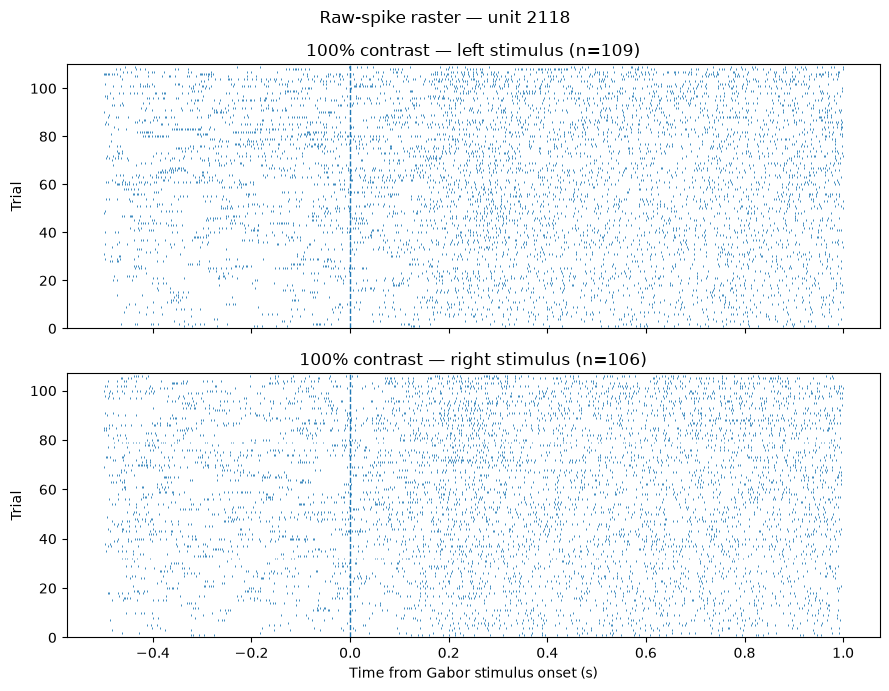

In [55]:
# Raster plot for the example unit
# 100% contrast, separated by stimulus side

example_spike_times_s = np.asarray(
    selected_spike_times[
        example_unit_position
    ],
    dtype=float,
)

stimulus_onset_times_s = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_onset_time"
    ],
    errors="coerce",
).to_numpy()


raster_conditions = [
    (
        "100% contrast — left stimulus",
        left_100_trial_mask,
    ),
    (
        "100% contrast — right stimulus",
        right_100_trial_mask,
    ),
]


fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(9, 7),
    sharex=True,
)


for ax, (
    condition_label,
    trial_mask,
) in zip(
    axes,
    raster_conditions,
):

    trial_positions = np.flatnonzero(
        trial_mask
    )

    for raster_row, trial_position in enumerate(
        trial_positions,
        start=1,
    ):

        stimulus_onset_s = (
            stimulus_onset_times_s[
                trial_position
            ]
        )

        absolute_window_start_s = (
            stimulus_onset_s
            + TIME_START_S
        )

        absolute_window_end_s = (
            stimulus_onset_s
            + TIME_END_S
        )


        first_spike_index = np.searchsorted(
            example_spike_times_s,
            absolute_window_start_s,
            side="left",
        )

        last_spike_index = np.searchsorted(
            example_spike_times_s,
            absolute_window_end_s,
            side="left",
        )


        relative_spike_times_s = (
            example_spike_times_s[
                first_spike_index:
                last_spike_index
            ]
            - stimulus_onset_s
        )


        ax.vlines(
            relative_spike_times_s,
            raster_row - 0.4,
            raster_row + 0.4,
            linewidth=0.6,
        )


    ax.axvline(
        0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_ylabel(
        "Trial"
    )

    ax.set_title(
        f"{condition_label} "
        f"(n={len(trial_positions)})"
    )

    ax.set_ylim(
        0,
        len(trial_positions) + 1,
    )


axes[-1].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

fig.suptitle(
    f"Raw-spike raster — unit {example_unit_index}"
)

plt.tight_layout()
save_figure(
    fig,
    "raster",
)

plt.show()

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\example_unit_100pct_PSTH.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\example_unit_100pct_PSTH.pdf


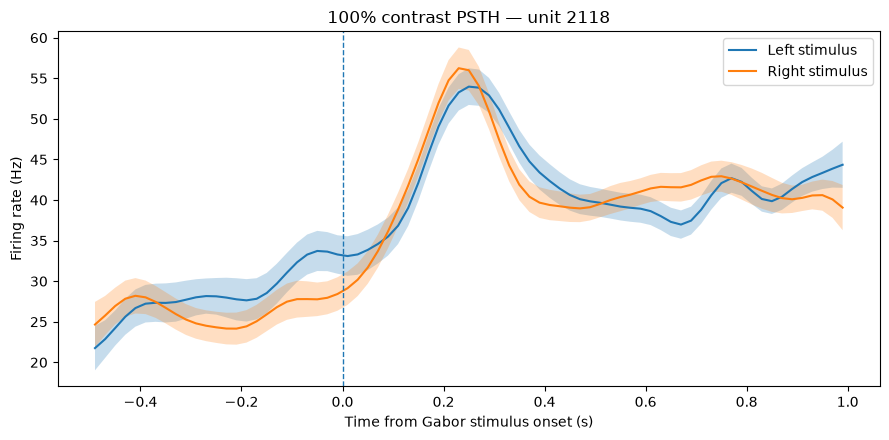

In [56]:
#  Peristimulus Time Histogram (PSTH) for the example unit
# 100% left versus right stimulus

def mean_and_sem(
    values,
):
    """
    values shape:
        trial × time
    """
    mean_values = values.mean(
        axis=0
    )

    sem_values = (
        values.std(
            axis=0,
            ddof=1,
        )
        / np.sqrt(
            values.shape[0]
        )
    )

    return (
        mean_values,
        sem_values,
    )
#left right
left_example_rates_hz = (
    smoothed_firing_rates_hz[
        left_100_trial_mask,
        example_unit_position,
        :,
    ]
)

right_example_rates_hz = (
    smoothed_firing_rates_hz[
        right_100_trial_mask,
        example_unit_position,
        :,
    ]
)


left_mean_hz, left_sem_hz = mean_and_sem(
    left_example_rates_hz
)

right_mean_hz, right_sem_hz = mean_and_sem(
    right_example_rates_hz
)

#plot
plt.figure(
    figsize=(9, 4.5)
)


plt.plot(
    time_bin_centers_s,
    left_mean_hz,
    label="Left stimulus",
)

plt.fill_between(
    time_bin_centers_s,
    left_mean_hz - left_sem_hz,
    left_mean_hz + left_sem_hz,
    alpha=0.25,
)


plt.plot(
    time_bin_centers_s,
    right_mean_hz,
    label="Right stimulus",
)

plt.fill_between(
    time_bin_centers_s,
    right_mean_hz - right_sem_hz,
    right_mean_hz + right_sem_hz,
    alpha=0.25,
)


plt.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel(
    "Time from Gabor stimulus onset (s)"
)

plt.ylabel(
    "Firing rate (Hz)"
)

plt.title(
    f"100% contrast PSTH — unit {example_unit_index}"
)

plt.legend()
plt.tight_layout()
save_figure(
    fig,
    "example_unit_100pct_PSTH",
)

plt.show()

In [16]:
# heatmap
# Define baseline window for population normalization

#更接近刺激前即时状态（边界；刺激后平滑污染）
BASELINE_START_S = -0.35
BASELINE_END_S = -0.15


baseline_mask = (
    (time_bin_centers_s >= BASELINE_START_S)
    & (time_bin_centers_s < BASELINE_END_S)
)


print(
    "Baseline bins:",
    int(baseline_mask.sum()),
)

print(
    "Baseline time centers:",
    time_bin_centers_s[baseline_mask],
)

Baseline bins: 10
Baseline time centers: [-0.35 -0.33 -0.31 -0.29 -0.27 -0.25 -0.23 -0.21 -0.19 -0.17]


In [17]:
#所有trial和unit的baseline
baseline_rates_hz = (
    smoothed_firing_rates_hz[
        :,
        :,
        baseline_mask,
    ]
)


print(
    "Baseline array shape:",
    baseline_rates_hz.shape,
)

Baseline array shape: (883, 40, 10)


In [18]:
#each unit baseline
baseline_mean_hz = (
    baseline_rates_hz
    .mean(
        axis=(0, 2)
    )
)


print(
    "Baseline mean shape:",
    baseline_mean_hz.shape,
)

print(
    "First 10 unit baseline means:",
    baseline_mean_hz[:10],
)

Baseline mean shape: (40,)
First 10 unit baseline means: [ 3.2756279  3.843266   4.1375303 18.318531   1.0049323  2.081383
  4.588947   1.1376288  3.3455486  1.5888857]


In [20]:
#each unit baseline SD
baseline_std_hz = (
    baseline_rates_hz
    .std(
        axis=(0, 2),
        ddof=1,
    )
)


print(
    "Baseline SD shape:",
    baseline_std_hz.shape,
)

#没有极小baseline_std_hz < 1e-6
print(
    "Minimum baseline SD:",
    baseline_std_hz.min(),
)

print(
    "Maximum baseline SD:",
    baseline_std_hz.max(),
)

Baseline SD shape: (40,)
Minimum baseline SD: 1.5357283
Maximum baseline SD: 31.89985


In [21]:
print(
    baseline_mean_hz.shape
)

print(
    baseline_mean_hz[
        None,
        :,
        None,
    ].shape
)

(40,)
(1, 40, 1)


In [22]:
# Baseline z-score each unit

z_firing_rates = (
    (
        smoothed_firing_rates_hz
        - baseline_mean_hz[
            None,
            :,
            None,
        ]
    )
    / baseline_std_hz[
        None,
        :,
        None,
    ]
)


print(
    "Z-scored firing-rate shape:",
    z_firing_rates.shape,
)

Z-scored firing-rate shape: (883, 40, 75)


In [23]:
#检查
z_baseline = (
    z_firing_rates[
        :,
        :,
        baseline_mask,
    ]
)


print(
    "Mean baseline z-score:",
    float(
        z_baseline.mean()
    ),
)

print(
    "Baseline z-score SD:",
    float(
        z_baseline.std(
            ddof=1
        )
    ),
)

Mean baseline z-score: -2.0957938886567717e-06
Baseline z-score SD: 0.9999475479125977


In [25]:
#从trial平均
left_100_population_z = (
    z_firing_rates[
        left_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


right_100_population_z = (
    z_firing_rates[
        right_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


print(
    "Left heatmap matrix:",
    left_100_population_z.shape,
)

print(
    "Right heatmap matrix:",
    right_100_population_z.shape,
)

Left heatmap matrix: (40, 75)
Right heatmap matrix: (40, 75)


In [26]:
#共同的 100% contrast response
all_100_trial_mask = (
    left_100_trial_mask
    | right_100_trial_mask
)


all_100_population_z = (
    z_firing_rates[
        all_100_trial_mask,
        :,
        :
    ]
    .mean(
        axis=0
    )
)


print(
    all_100_population_z.shape
)
# (40, 75)

(40, 75)


In [27]:
#sort by peak latency

#response window
sorting_response_mask = (
    (time_bin_centers_s >= 0.05)
    & (time_bin_centers_s < 0.40)
)

#提取
sorting_response = (
    all_100_population_z[
        :,
        sorting_response_mask,
    ]
)


print(
    sorting_response.shape
)

peak_bin_within_window = np.argmax(
    sorting_response,
    axis=1,
)

sorting_times_s = (
    time_bin_centers_s[
        sorting_response_mask
    ]
)

peak_latency_s = (
    sorting_times_s[
        peak_bin_within_window
    ]
)

unit_sort_order = np.argsort(
    peak_latency_s
)

(40, 18)


In [28]:
left_100_sorted_z = (
    left_100_population_z[
        unit_sort_order,
        :
    ]
)

right_100_sorted_z = (
    right_100_population_z[
        unit_sort_order,
        :
    ]
)

In [29]:
#color scale
combined_abs_z = np.concatenate(
    [
        np.abs(
            left_100_sorted_z.ravel()
        ),
        np.abs(
            right_100_sorted_z.ravel()
        ),
    ]
)


color_limit = np.percentile(
    combined_abs_z,
    99,
)


print(
    "Symmetric color limit:",
    color_limit,
)

Symmetric color limit: 2.6087766


Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\heatmap_100pct_left_right.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\heatmap_100pct_left_right.pdf


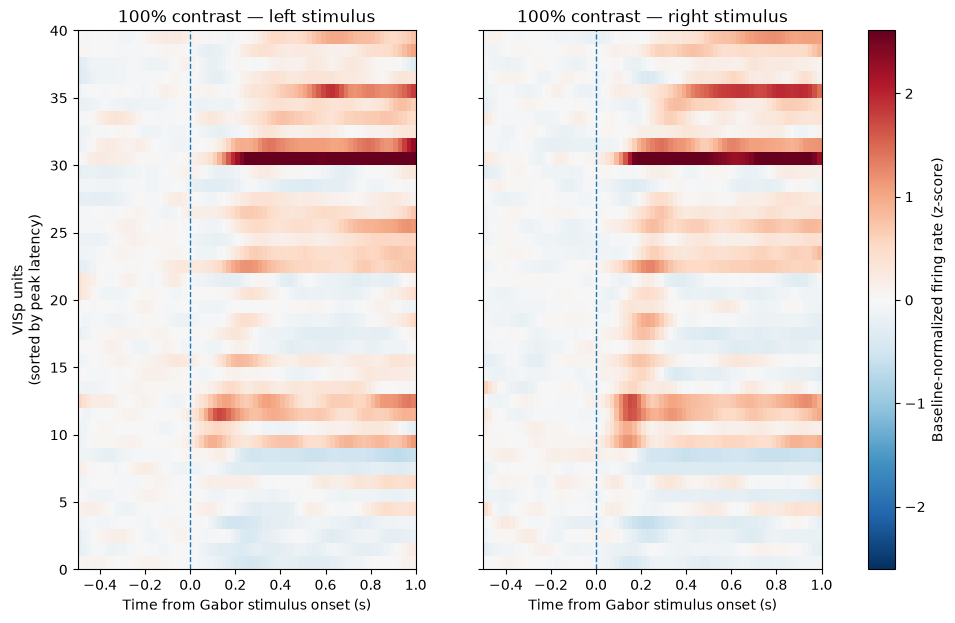

In [57]:
# Population heatmaps
# 100% contrast: left vs right stimulus

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    sharex=True,
    sharey=True,
)


left_image = axes[0].imshow(
    left_100_sorted_z,
    aspect="auto",
    origin="lower",
    extent=[
        TIME_START_S,
        TIME_END_S,
        0,
        len(selected_units_df),
    ],
    vmin=-color_limit,
    vmax=color_limit,
    cmap="RdBu_r",
)


axes[0].axvline(
    0,
    linestyle="--",
    linewidth=1,
)

axes[0].set_title(
    "100% contrast — left stimulus"
)

axes[0].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)

axes[0].set_ylabel(
    "VISp units\n(sorted by peak latency)"
)


right_image = axes[1].imshow(
    right_100_sorted_z,
    aspect="auto",
    origin="lower",
    extent=[
        TIME_START_S,
        TIME_END_S,
        0,
        len(selected_units_df),
    ],
    vmin=-color_limit,
    vmax=color_limit,
    cmap="RdBu_r",
)


axes[1].axvline(
    0,
    linestyle="--",
    linewidth=1,
)

axes[1].set_title(
    "100% contrast — right stimulus"
)

axes[1].set_xlabel(
    "Time from Gabor stimulus onset (s)"
)


colorbar = fig.colorbar(
    right_image,
    ax=axes,
    label="Baseline-normalized firing rate (z-score)",
)

save_figure(
    fig,
    "heatmap_100pct_left_right",
)

plt.show()

In [33]:
#PCA

#label
contrast_values = pd.to_numeric(
    valid_trials_df[
        "gabor_stimulus_contrast"
    ],
    errors="coerce",
).to_numpy()

stimulus_sides = (
    valid_trials_df[
        "gabor_stimulus_side"
    ]
    .astype(str)
    .str.strip()
    .to_numpy()
)


left_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "left")
)

right_100_trial_mask = (
    (contrast_values == 100.0)
    & (stimulus_sides == "right")
)


print(
    "100% left trials:",
    left_100_trial_mask.sum(),
)

print(
    "100% right trials:",
    right_100_trial_mask.sum(),
)

100% left trials: 109
100% right trials: 106


In [34]:
#trail average
left_100_mean_z = (
    z_firing_rates[
        left_100_trial_mask,
        :,
        :
    ]
    .mean(axis=0)
)
right_100_mean_z = (
    z_firing_rates[
        right_100_trial_mask,
        :,
        :
    ]
    .mean(axis=0)
)


print(
    "Left mean shape:",
    left_100_mean_z.shape,
)

print(
    "Right mean shape:",
    right_100_mean_z.shape,
)

Left mean shape: (40, 75)
Right mean shape: (40, 75)


In [35]:
#转置time*unit
left_states = (
    left_100_mean_z.T
)

right_states = (
    right_100_mean_z.T
)


print(
    "Left states:",
    left_states.shape,
)

print(
    "Right states:",
    right_states.shape,
)

Left states: (75, 40)
Right states: (75, 40)


In [36]:
#PCA input
pca_input = np.concatenate(
    [
        left_states,
        right_states,
    ],
    axis=0,
)


print(
    "PCA input shape:",
    pca_input.shape,
)

PCA input shape: (150, 40)


In [42]:
#PCA
from sklearn.decomposition import PCA
from sklearn import set_config

set_config(
    display="text"
)
pca = PCA(
    n_components=3
)

pca.fit(
    pca_input
)



print(
    "Components shape:",
    pca.components_.shape,
)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_,
)

Components shape: (3, 40)
Explained variance ratio: [0.7317082  0.11931291 0.04152302]


In [44]:
#PC123
explained_variance_ratio = (
    pca.explained_variance_ratio_
)


print(
    "PC1 explained variance:",
    explained_variance_ratio[0],
)

print(
    "PC2 explained variance:",
    explained_variance_ratio[1],
)

print(
    "PC3 explained variance:",
    explained_variance_ratio[2],
)

print(
    "PC1–3 cumulative variance:",
    explained_variance_ratio[:3].sum(),
)

PC1 explained variance: 0.7317082
PC2 explained variance: 0.11931291
PC3 explained variance: 0.041523017
PC1–3 cumulative variance: 0.8925442


In [45]:
left_pca = pca.transform(
    left_states
)

right_pca = pca.transform(
    right_states
)


print(
    "Left PCA shape:",
    left_pca.shape,
)

print(
    "Right PCA shape:",
    right_pca.shape,
)

Left PCA shape: (75, 3)
Right PCA shape: (75, 3)


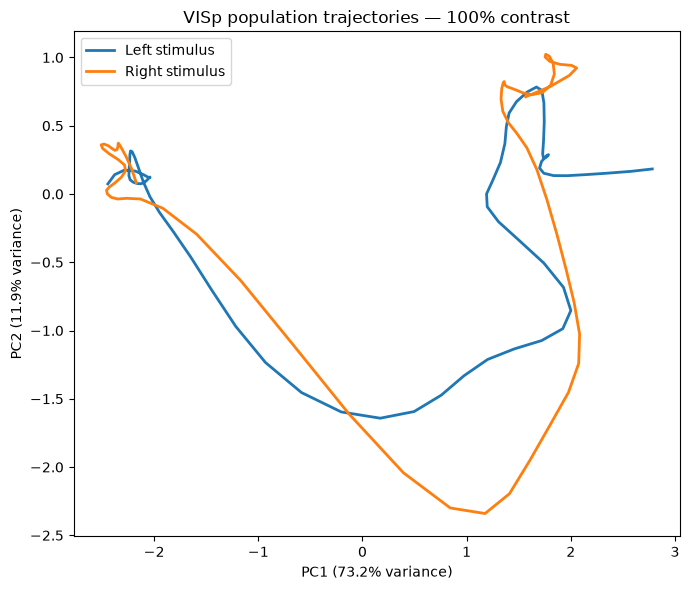

In [46]:
#PC12 trajectory
plt.figure(
    figsize=(7, 6)
)


plt.plot(
    left_pca[:, 0],
    left_pca[:, 1],
    label="Left stimulus",
    linewidth=2,
)

plt.plot(
    right_pca[:, 0],
    right_pca[:, 1],
    label="Right stimulus",
    linewidth=2,
)


plt.xlabel(
    f"PC1 "
    f"({explained_variance_ratio[0] * 100:.1f}% variance)"
)

plt.ylabel(
    f"PC2 "
    f"({explained_variance_ratio[1] * 100:.1f}% variance)"
)

plt.title(
    "VISp population trajectories — 100% contrast"
)

plt.legend()

plt.tight_layout()
plt.show()

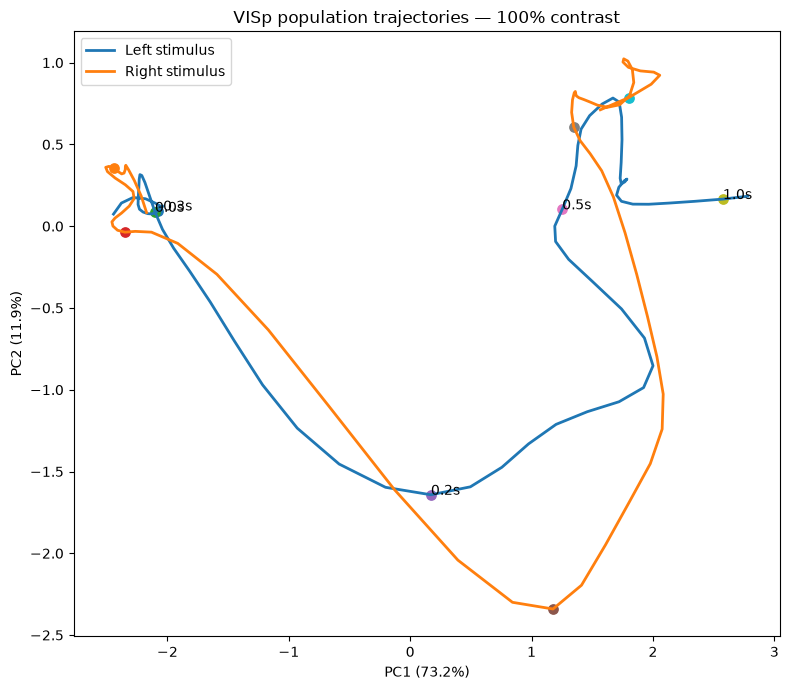

In [47]:
#time marker
def nearest_time_index(
    time_values,
    target_time,
):
    return int(
        np.argmin(
            np.abs(
                time_values
                - target_time
            )
        )
    )


time_markers_s = [
    -0.3,
    0.0,
    0.2,
    0.5,
    0.98,
]


time_marker_indices = [
    nearest_time_index(
        time_bin_centers_s,
        target_time,
    )
    for target_time
    in time_markers_s
]

fig, ax = plt.subplots(
    figsize=(8, 7)
)


ax.plot(
    left_pca[:, 0],
    left_pca[:, 1],
    linewidth=2,
    label="Left stimulus",
)

ax.plot(
    right_pca[:, 0],
    right_pca[:, 1],
    linewidth=2,
    label="Right stimulus",
)


for (
    target_time,
    time_index,
) in zip(
    time_markers_s,
    time_marker_indices,
):

    ax.scatter(
        left_pca[
            time_index,
            0,
        ],
        left_pca[
            time_index,
            1,
        ],
        s=45,
    )

    ax.scatter(
        right_pca[
            time_index,
            0,
        ],
        right_pca[
            time_index,
            1,
        ],
        s=45,
    )


    ax.annotate(
        f"{target_time:.1f}s",
        (
            left_pca[
                time_index,
                0,
            ],
            left_pca[
                time_index,
                1,
            ],
        ),
    )


ax.set_xlabel(
    f"PC1 "
    f"({explained_variance_ratio[0] * 100:.1f}%)"
)

ax.set_ylabel(
    f"PC2 "
    f"({explained_variance_ratio[1] * 100:.1f}%)"
)

ax.set_title(
    "VISp population trajectories — 100% contrast"
)

ax.legend()

plt.tight_layout()
plt.show()

Saved PNG: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\PCA_100pct_left_right.png
Saved PDF: D:\Ephys_analysis\ibl-population-dynamics\results\figures\Primary_visual_area_e349a2e7\PCA_100pct_left_right.pdf


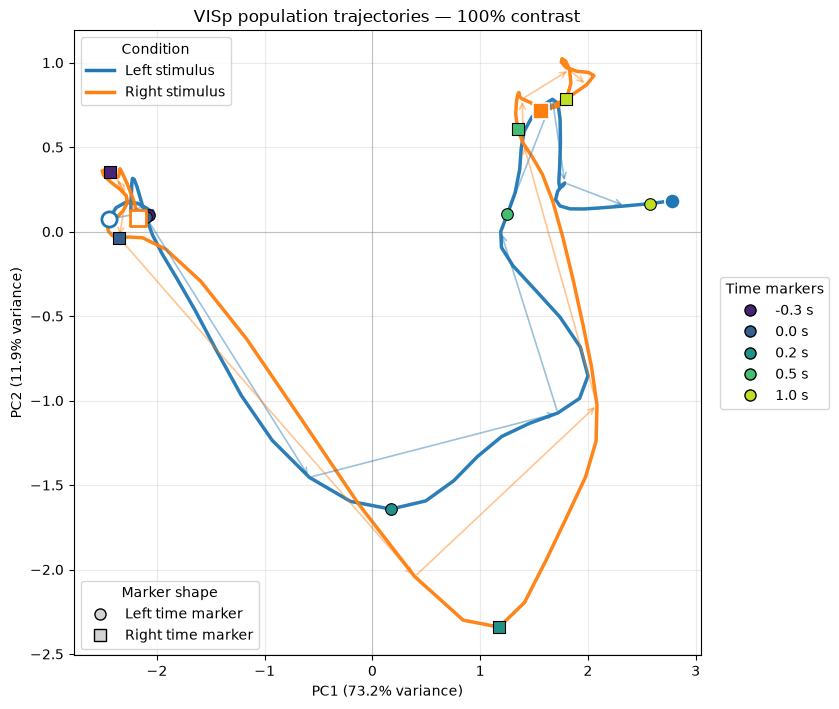

In [58]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Helper: nearest time index
# ------------------------------------------------------------
def nearest_time_index(time_values, target_time):
    return int(np.argmin(np.abs(time_values - target_time)))


# ------------------------------------------------------------
# Choose time markers
# ------------------------------------------------------------
time_markers_s = [-0.3, 0.0, 0.2, 0.5, 0.98]

time_marker_indices = [
    nearest_time_index(time_bin_centers_s, t)
    for t in time_markers_s
]

# consistent colors for time points
time_marker_colors = plt.cm.viridis(
    np.linspace(0.1, 0.9, len(time_markers_s))
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 7.2))

# main trajectories
ax.plot(
    left_pca[:, 0],
    left_pca[:, 1],
    color="tab:blue",
    lw=2.5,
    alpha=0.95,
    label="Left stimulus",
)

ax.plot(
    right_pca[:, 0],
    right_pca[:, 1],
    color="tab:orange",
    lw=2.5,
    alpha=0.95,
    label="Right stimulus",
)


# ------------------------------------------------------------
# Add direction arrows every few bins
# ------------------------------------------------------------
def add_direction_arrows(ax, traj, color, step=8):
    for i in range(0, len(traj) - step, step):
        ax.annotate(
            "",
            xy=(traj[i + step, 0], traj[i + step, 1]),
            xytext=(traj[i, 0], traj[i, 1]),
            arrowprops=dict(
                arrowstyle="->",
                color=color,
                lw=1.2,
                alpha=0.45,
            ),
        )

add_direction_arrows(ax, left_pca, "tab:blue", step=8)
add_direction_arrows(ax, right_pca, "tab:orange", step=8)


# ------------------------------------------------------------
# Add time markers
# same color = same time
# circle = left
# square = right
# ------------------------------------------------------------
for marker_color, time_idx in zip(time_marker_colors, time_marker_indices):
    ax.scatter(
        left_pca[time_idx, 0],
        left_pca[time_idx, 1],
        s=70,
        marker="o",
        facecolor=marker_color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
    )

    ax.scatter(
        right_pca[time_idx, 0],
        right_pca[time_idx, 1],
        s=70,
        marker="s",
        facecolor=marker_color,
        edgecolor="black",
        linewidth=0.8,
        zorder=6,
    )


# ------------------------------------------------------------
# Highlight start and end points
# ------------------------------------------------------------
ax.scatter(
    left_pca[0, 0], left_pca[0, 1],
    s=120, marker="o",
    facecolor="white", edgecolor="tab:blue",
    linewidth=2.0, zorder=7
)
ax.scatter(
    right_pca[0, 0], right_pca[0, 1],
    s=120, marker="s",
    facecolor="white", edgecolor="tab:orange",
    linewidth=2.0, zorder=7
)

ax.scatter(
    left_pca[-1, 0], left_pca[-1, 1],
    s=120, marker="o",
    facecolor="tab:blue", edgecolor="white",
    linewidth=1.2, zorder=7
)
ax.scatter(
    right_pca[-1, 0], right_pca[-1, 1],
    s=120, marker="s",
    facecolor="tab:orange", edgecolor="white",
    linewidth=1.2, zorder=7
)


# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------
ax.set_xlabel(
    f"PC1 ({explained_variance_ratio[0] * 100:.1f}% variance)"
)
ax.set_ylabel(
    f"PC2 ({explained_variance_ratio[1] * 100:.1f}% variance)"
)
ax.set_title(
    "VISp population trajectories — 100% contrast"
)

ax.grid(alpha=0.25)
ax.axhline(0, color="gray", lw=0.8, alpha=0.4)
ax.axvline(0, color="gray", lw=0.8, alpha=0.4)


# ------------------------------------------------------------
# Legend 1: condition (line color)
# ------------------------------------------------------------
condition_handles = [
    Line2D([0], [0], color="tab:blue", lw=2.5, label="Left stimulus"),
    Line2D([0], [0], color="tab:orange", lw=2.5, label="Right stimulus"),
]

legend1 = ax.legend(
    handles=condition_handles,
    loc="upper left",
    frameon=True,
    title="Condition",
)
ax.add_artist(legend1)


# ------------------------------------------------------------
# Legend 2: marker shape
# ------------------------------------------------------------
shape_handles = [
    Line2D(
        [0], [0],
        marker="o", linestyle="None",
        markerfacecolor="lightgray",
        markeredgecolor="black",
        markersize=8,
        label="Left time marker",
    ),
    Line2D(
        [0], [0],
        marker="s", linestyle="None",
        markerfacecolor="lightgray",
        markeredgecolor="black",
        markersize=8,
        label="Right time marker",
    ),
]

legend2 = ax.legend(
    handles=shape_handles,
    loc="lower left",
    frameon=True,
    title="Marker shape",
)
ax.add_artist(legend2)


# ------------------------------------------------------------
# Legend 3: time-color mapping
# ------------------------------------------------------------
time_handles = [
    Line2D(
        [0], [0],
        marker="o", linestyle="None",
        markerfacecolor=c,
        markeredgecolor="black",
        markersize=8,
        label=f"{t:.1f} s",
    )
    for c, t in zip(time_marker_colors, time_markers_s)
]

legend3 = ax.legend(
    handles=time_handles,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    title="Time markers",
)

plt.tight_layout()
save_figure(
    fig,
    "PCA_100pct_left_right",
)

plt.show()